In [2]:
from typing import Callable, Literal
from functools import partial

import sys
import numpy as np
import jax.numpy as jnp
import flax.linen as nn
import jax
from jax import vmap, jit, random, grad
from jax.nn.initializers import normal, xavier_uniform
from torch.utils.data import Dataset
from einops import rearrange
import platform
from PIL import Image
import matplotlib.pyplot as plt
import optax
from tqdm import trange
from typing import Sequence
import itertools
from sklearn.metrics import confusion_matrix

In [2]:
print("Python:", sys.executable)
print("JAX devices:", jax.devices())

Python: /home/cnagata/miniforge3/envs/enm5310/bin/python
JAX devices: [cuda(id=0)]


In [26]:
gpu = jax.devices("gpu")[0]
stats = gpu.memory_stats()
print(stats)
print("gb in use: ",stats['bytes_in_use']/1e9)
print("limit (gb): ",stats['pool_bytes']/1e9)
print("percent used: ",stats['bytes_in_use']/stats['pool_bytes'])

{'num_allocs': 344, 'bytes_in_use': 2352384, 'peak_bytes_in_use': 618580224, 'largest_alloc_size': 614400000, 'bytes_limit': 9663184896, 'bytes_reserved': 0, 'peak_bytes_reserved': 0, 'largest_free_block_bytes': 0, 'pool_bytes': 9663184896, 'peak_pool_bytes': 9663184896}
gb in use:  0.002352384
limit (gb):  9.663184896
percent used:  0.00024343775114701066


In [3]:
print("Operating system:", platform.system())
print("JAX backend:", jax.default_backend())
print("JAX devices:", jax.devices())
!nvidia-smi


Operating system: Linux
JAX backend: gpu
JAX devices: [cuda(id=0)]


/home/cnagata/miniforge3/envs/enm5310/lib/python3.9/pty.py:85: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


Sat Nov 21 23:42:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.07             Driver Version: 581.80         CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3060        On  |   00000000:08:00.0  On |                  N/A |
|  0%   36C    P2             34W /  170W |    1678MiB /  12288MiB |      1%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# ENM 5310 Fall 2026: Coding Assignment 2

## Compute and Run Times

If implemented properly and efficiently, each problem should take **less than 10 minutes** on the free T4 GPU in Google Colab.

**Tip:** To avoid running out of GPU credits, develop, write, and debug your models on the CPU, then switch to the GPU for training.

My solution run times in Google Colab (for the entire problem, using JAX with `vmap` and `jit` where appropriate):

| Problem | Run time |
|---|---|
| 1 | 1.5 minutes |
| 2 | 4.0 minutes |
| 3 | 3.5 minutes |
| 4 | 1.0 minute |
| 5 | 10.0 minutes |

If your run times are significantly longer, your code is likely inefficient. Feel free to come to my office hours to discuss.

# Problem 1 (MLP + Fourier Features) [20 points]

Load the image `130034.jpg` from [https://github.com/BIDS/BSDS500/blob/master/BSDS500/data/images/train/130034.jpg](https://github.com/BIDS/BSDS500/blob/master/BSDS500/data/images/train/130034.jpg) and downsample it by a factor of 2 to a resolution of $160\times240$ to make training cheaper. Scale the RGB values to $[0,1]$ and map each pixel to its coordinates $(x_1, x_2)\in[0,1]^2$ on a uniform grid, giving $160\times240=38400$ training points.

The task in both parts is the regression $(x_1, x_2)\mapsto(r, g, b)$.

The [Flax MLP notebook](https://github.com/PredictiveIntelligenceLab/ENM5310/blob/main/notebooks/Flax_MLP.ipynb) from class may be helpful as starter code.

(321, 481, 3)
(160, 240, 3)


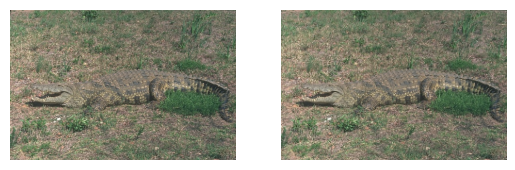

(38400, 2)
(38400, 3)


In [4]:
img = Image.open("130034.jpg")
img = jnp.asarray(img)
print(img.shape)

def downsample(image):
    image=image.astype(float)
    if image.shape[0] % 2 == 1:
        clip_x = 1
    else:
        clip_x = 0

    if image.shape[1] % 2 == 1:
        clip_y = 1
    else:
        clip_y = 0
    return (
        image[clip_x + 0::2, clip_y + 0::2] +
        image[clip_x + 1::2, clip_y + 0::2] +
        image[clip_x + 0::2, clip_y + 1::2] +
        image[clip_x + 1::2, clip_y + 1::2]
    ) / 4 /255

img_downsampled = downsample(img)
print(img_downsampled.shape)

fig, ax = plt.subplots(1,2)
ax[0].imshow(img)
ax[1].imshow(img_downsampled)
ax[0].axis("off")
ax[1].axis("off")
plt.show()

height, width = img_downsampled.shape[:2]
rows = jnp.linspace(0,1,height)
cols = jnp.linspace(0,1,width)

row_grid, col_grid = jnp.meshgrid(rows, cols, indexing="ij")

X = jnp.stack([row_grid, col_grid], axis=-1).reshape(-1,2)
Y = jnp.asarray(img_downsampled).reshape(-1, 3)
print(X.shape)
print(Y.shape)

## Part 1 (Baseline MLP)

Train an MLP with **3 hidden layers** of 128 neurons each, using a $\tanh$ activation function, followed by a **linear output layer** with 3 neurons (one per RGB channel). Apply a sigmoid to the output so the predictions lie in $[0,1]$. The full layer sizes are $[2, 128, 128, 128, 3]$.

**Training:** Use the mean squared error loss and the [Adam](https://arxiv.org/pdf/1412.6980) optimizer with a constant learning rate of 1e-03. Train for 25000 steps with a batch size of 256.


In [4]:
class MLP(nn.Module):
    num_layers: int=3
    hidden_dim: int=128
    output_dim: int=2
    activation: Callable=nn.tanh

    @nn.compact
    def __call__(self, x):
        for _ in range(self.num_layers):
            x = nn.Dense(self.hidden_dim)(x)
            x = self.activation(x)
        x = nn.Dense(self.output_dim)(x)
        x = nn.sigmoid(x)
        return x

## Part 2 (MLP + Fourier Features)

Add Gaussian [Fourier features](https://arxiv.org/pdf/2006.10739) (section 6.1) to the beginning of the Part 1 model. Use 64 frequencies, so $\mathbf{B}\in\mathbb{R}^{2\times64}$, initialize $\mathbf{B}$ with entries drawn from $\mathcal{N}(0, 10^2)$ (standard deviation 10), and make $\mathbf{B}$ **learnable**. The 128-dimensional feature vector $\gamma(x)$ is the input to the MLP, so the full layer sizes are $[128, 128, 128, 128, 3]$, with the same 3 hidden layers, linear output layer, and sigmoid as Part 1.

Use the same loss, optimizer, learning rate, number of steps, and batch size as Part 1.

Fourier features will be discussed later in the class, but here is a brief overview (also refer to the paper): Fourier features map low-dimensional inputs $x \in \mathbb{R}^d$ (a row vector) to a higher-dimensional space using sinusoidal functions of multiple frequencies, of the form $\gamma(x)=[\cos(2\pi x\mathbf{B}),\sin(2\pi x\mathbf{B})]$, where $\mathbf{B}\in\mathbb{R}^{d\times m}$ is a fixed or learnable frequency matrix ($d=2$ and $m=64$ here). Fourier features make it easier for neural networks to represent high-frequency functions by building a high-frequency inductive bias into the feature space.

In [5]:
class MLP_Fourier(nn.Module):
    num_frequencies: int=64
    num_layers: int=3
    hidden_dim: int=128
    output_dim: int=2
    activation: Callable=nn.tanh

    @nn.compact
    def __call__(self, x):
        B = self.param("B",nn.initializers.normal(10),(x.shape[1],self.num_frequencies))
        x_B = x @ B
        x = jnp.concatenate([jnp.cos(2*jnp.pi* x_B),jnp.sin(2*jnp.pi* x_B)],axis = -1)
        for _ in range(self.num_layers):
            x = nn.Dense(self.hidden_dim)(x)
            x = self.activation(x)
        x = nn.Dense(self.output_dim)(x)
        x = nn.sigmoid(x)
        return x



## Deliverables

1. Plot the training losses of the Part 1 and Part 2 models on the same figure, with the y-axis on a log scale.
2. Plot the ground truth image next to the reconstructed images from both models.
3. Plot the pointwise absolute error (averaged over the RGB channels) for both models, and report the relative $L^2$ error (in %) between the reconstructed and ground truth images for each model.
4. Report your findings: compare the reconstructions from Part 1 and Part 2, and explain why the Fourier features change what the network is able to learn.

In [ ]:
class MLPregression:
    # Initialize the class
    def __init__(self, arch, batch, rng_key=random.PRNGKey(0)):
        
        # Initialization and evaluation functions
        inputs, _ = batch
        self.model = arch
        self.params = self.model.init(rng_key, inputs)
        print(self.model.tabulate(rng_key, inputs))

        # Optimizer
        lr = 1e-3
        self.optimizer = optax.adam(learning_rate=lr)
        self.opt_state = self.optimizer.init(self.params)

        # Logger
        self.loss_log = []

    def loss(self, params, batch):
        inputs, targets = batch
        outputs = self.model.apply(params, inputs)
        loss = jnp.mean((targets - outputs)**2)
        return loss 

    # Define a compiled update step
    @partial(jit, static_argnums=(0,))
    def step(self, params, opt_state, batch):
        grads = grad(self.loss)(params, batch)
        updates, opt_state = self.optimizer.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)
        return params, opt_state


    # Optimize parameters in a loop
    def train(self, dataset, nIter = 10000):
        data = iter(dataset)
        pbar = trange(nIter)
        # Main training loop
        for it in pbar:
            batch = next(data)
            self.params, self.opt_state = self.step(self.params, self.opt_state, batch)
            # Logger
            if it % 100 == 0:
                loss = self.loss(self.params, batch)
                self.loss_log.append(loss)
                pbar.set_postfix({'loss': loss})

In [7]:
class DataGenerator(Dataset):
    def __init__(self, X, y, batch_size, rng_key=random.PRNGKey(1234)):
        self.X = X
        self.y = y
        self.N = y.shape[0]
        self.batch_size = batch_size
        self.key = rng_key

    @partial(jit, static_argnums=(0,))
    def data_generation(self, key, X, y):
        idx = random.choice(key, self.N, (self.batch_size,), replace=False)
        X = X[idx]
        y = y[idx]
        return X, y

    def __getitem__(self, index):
        self.key = random.split(self.key, 1)[0]
        X, y = self.data_generation(self.key, self.X, self.y)
        return X, y

In [8]:
dataset = DataGenerator(X, Y, 256)
data = iter(dataset)
batch = next(data)

## Part 1

In [9]:
arch = MLP(num_layers=3,
           hidden_dim=128,
           output_dim=3)
model = MLPregression(arch, batch)


                                  MLP Summary                                   
┏━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ path    ┃ module ┃ inputs           ┃ outputs          ┃ params              ┃
┡━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│         │ MLP    │ float32[256,2]   │ float32[256,3]   │                     │
├─────────┼────────┼──────────────────┼──────────────────┼─────────────────────┤
│ Dense_0 │ Dense  │ float32[256,2]   │ float32[256,128] │ bias: float32[128]  │
│         │        │                  │                  │ kernel:             │
│         │        │                  │                  │ float32[2,128]      │
│         │        │                  │                  │                     │
│         │        │                  │                  │ 384 (1.5 KB)        │
├─────────┼────────┼──────────────────┼──────────────────┼─────────────────────┤
│ Dense_1 │ Dense  │ float3

In [10]:
model.train(dataset, nIter=25000)

100%|██████████| 25000/25000 [00:44<00:00, 562.22it/s, loss=0.004850469] 


Error 1.582374e-01


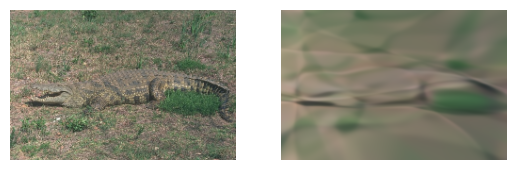

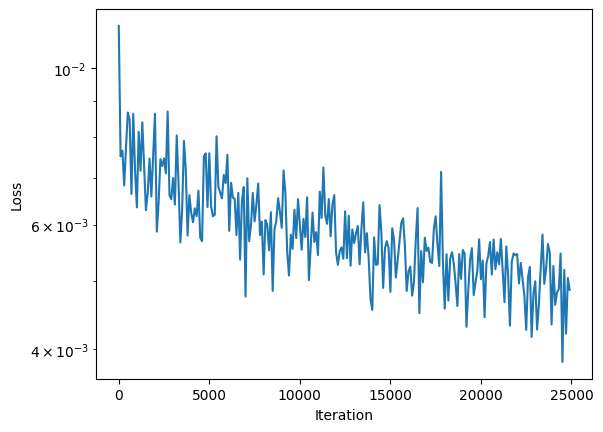

In [11]:
Y_pred = model.model.apply(model.params, X)
img_reconstructed = Y_pred.reshape(height, width, 3)

error = jnp.linalg.norm(Y_pred - Y)/jnp.linalg.norm(Y)
print('Error %e' %(error))

fig, ax = plt.subplots(1,2)
ax[0].imshow(img_downsampled)
ax[1].imshow(img_reconstructed)
ax[0].axis("off")
ax[1].axis("off")

plt.figure()
plt.plot(jnp.arange(len(model.loss_log)) * 100,jnp.array(model.loss_log))
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.show()


## Part 2

In [12]:
arch_fourier = MLP_Fourier(num_frequencies = 64, num_layers=3,
           hidden_dim=128,
           output_dim=3)
model_fourier = MLPregression(arch_fourier, batch)


                              MLP_Fourier Summary                               
┏━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ path    ┃ module      ┃ inputs          ┃ outputs          ┃ params          ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│         │ MLP_Fourier │ float32[256,2]  │ float32[256,3]   │ B:              │
│         │             │                 │                  │ float32[2,64]   │
│         │             │                 │                  │                 │
│         │             │                 │                  │ 128 (512 B)     │
├─────────┼─────────────┼─────────────────┼──────────────────┼─────────────────┤
│ Dense_0 │ Dense       │ float32[256,12… │ float32[256,128] │ bias:           │
│         │             │                 │                  │ float32[128]    │
│         │             │                 │                  │ kernel:         │
│         │             │  

In [13]:
model_fourier.train(dataset, nIter=25000)

100%|██████████| 25000/25000 [00:45<00:00, 551.69it/s, loss=0.0003447345] 


Error 4.473170e-02


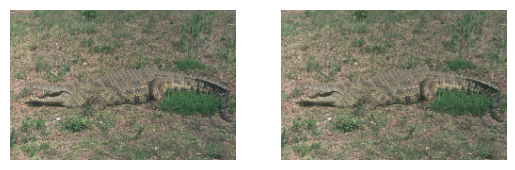

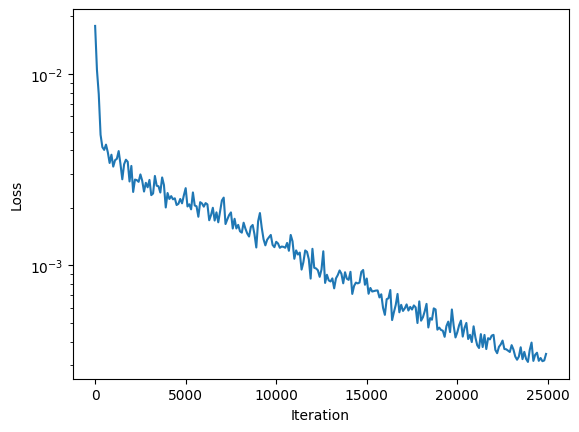

In [14]:
Y_pred = model_fourier.model.apply(model_fourier.params, X)
img_reconstructed = Y_pred.reshape(height, width, 3)

error = jnp.linalg.norm(Y_pred - Y)/jnp.linalg.norm(Y)
print('Error %e' %(error))

fig, ax = plt.subplots(1,2)
ax[0].imshow(img_downsampled)
ax[1].imshow(img_reconstructed)
ax[0].axis("off")
ax[1].axis("off")

plt.figure()
plt.plot(jnp.arange(len(model_fourier.loss_log)) * 100,jnp.array(model_fourier.loss_log))
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.show()

# Problem 2 (CNN + Data Augmentation) [20 points]

Both parts use the [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html), with pixel values scaled to $[0,1]$.

The following function can be used to download the data, where `split` is either `"train"` or `"test"`:

```python
import io
import pandas as pd
from PIL import Image

def load_cifar10(split):
    url = f"https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/{split}-00000-of-00001.parquet"
    df = pd.read_parquet(url)
    images = np.stack([np.asarray(Image.open(io.BytesIO(d["bytes"]))) for d in df["img"]])
    targets = df["label"].to_numpy()
    return images, targets
```

These may be helpful:
- [Flax CNN notebook](https://github.com/PredictiveIntelligenceLab/ENM5310/blob/main/notebooks/Flax_CNN.ipynb) from class
- [Inception, ResNet and DenseNet](https://uvadlc-notebooks.readthedocs.io/en/latest/tutorial_notebooks/JAX/tutorial5/Inception_ResNet_DenseNet.html) tutorial

In [6]:
import io
import pandas as pd
from PIL import Image

def load_cifar10(split):
    url = f"https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/{split}-00000-of-00001.parquet"
    df = pd.read_parquet(url)
    images = np.stack([np.asarray(Image.open(io.BytesIO(d["bytes"]))) for d in df["img"]])
    targets = df["label"].to_numpy()
    return images, targets

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()

## Part 1 (Baseline CNN)

Train the following [convolutional neural network](https://galileo-unbound.blog/wp-content/uploads/2025/02/lecun.neco_.1989.1.4.541.pdf):

| Layer | Details | Output shape |
|---|---|---|
| Input | 32x32x3 images | 32x32x3 |
| Convolution + ReLU | 6 filters, 5x5, stride 1 | 32x32x6 |
| Max pooling | 2x2, stride 2 | 16x16x6 |
| Convolution + ReLU | 12 filters, 5x5, stride 1 | 16x16x12 |
| Max pooling | 2x2, stride 2 | 8x8x12 |
| Convolution + ReLU | 24 filters, 5x5, stride 1 | 8x8x24 |
| Max pooling | 2x2, stride 2 | 4x4x24 |
| Fully connected | Flatten, then layers [384, 120, 60, 10] with ReLU on all layers but the last | 10 |

Notice how the number of filters doubles at each convolution while each max pooling halves the feature resolution. Use the appropriate amount of padding so each convolution keeps the spatial resolution of its input.

**Training:** Use the multi-class cross entropy loss and the [Adam](https://arxiv.org/pdf/1412.6980) optimizer with a constant learning rate of 1e-03. Train for 20000 steps with a batch size of 128.

**Note:** You must write out the cross entropy loss yourself. Using `optax.softmax_cross_entropy` is **not** allowed.


In [3]:
class ConvNet(nn.Module):
    out_channels: Sequence[int]
    dense_layers: Sequence[int]
    activation: Callable=nn.relu

    @nn.compact
    def __call__(self, x, training = False):
        for i in range(len(self.out_channels)):
            x = nn.Conv(self.out_channels[i],  kernel_size=(5,5), strides=(1,1), padding="SAME")(x)
            x = self.activation(x)
            x = nn.max_pool(x, (2,2), (2,2))
        x = x.flatten()
        for i in range(len(self.dense_layers)-1):
            x = nn.Dense(self.dense_layers[i])(x)
            x = self.activation(x)
        x = nn.Dense(self.dense_layers[-1])(x)
        if not training:
            x = nn.softmax(x)
        return x

In [4]:
class CNNclassifier:
    # Initialize the class
    def __init__(self, arch, rng_key=random.PRNGKey(0)):
        
        # Initialization and evaluation functions
        inputs = jnp.ones((32,32,3))
        self.model = arch
        self.params = self.model.init(rng_key, inputs)
        print(self.model.tabulate(rng_key, inputs))
        self.apply = vmap(self.model.apply, in_axes=(None,0,None))

        # Optimizer
        lr = 1e-3
        self.optimizer = optax.adam(learning_rate=lr)
        self.opt_state = self.optimizer.init(self.params)

        # Logger
        self.loss_log = []

    def loss(self, params, batch):
        images, labels = batch
        logit = self.apply(params, images, True)
        logit_shifted = logit - jnp.max(logit, axis=-1, keepdims=True)
        log_outputs = logit_shifted - jnp.log(jnp.sum(jnp.exp(logit_shifted),axis = -1, keepdims=True))
        loss = -jnp.sum(labels*log_outputs,axis = 1)
        return jnp.mean(loss)

    # Define a compiled update step
    @partial(jit, static_argnums=(0,))
    def step(self, params, opt_state, batch):
        grads = grad(self.loss)(params, batch)
        updates, opt_state = self.optimizer.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)
        return params, opt_state

    # Optimize parameters in a loop
    def train(self, dataset, nIter = 10000):
        data = iter(dataset)
        pbar = trange(nIter)
        # Main training loop
        for it in pbar:
            batch = next(data)
            self.params, self.opt_state = self.step(self.params, self.opt_state, batch)
            # Logger
            if it % 100 == 0:
                loss = self.loss(self.params, batch)
                self.loss_log.append(loss)
                pbar.set_postfix({'loss': loss})

## Part 2 (Larger Model + Data Augmentation)

In this part you will train a wider CNN using **data augmentation**, where each training batch is randomly transformed so the network rarely sees exactly the same image twice.

You are given an `AugDataGenerator` that applies two augmentations to every training batch:

- **Random horizontal flip:** each image is mirrored left to right with probability 0.5.
- **Random crop:** each image is reflect padded by 4 pixels on every side (32x32 → 40x40) and a random 32x32 window is cropped out, shifting the image by up to ±4 pixels in each direction.

Train the following wider CNN using `AugDataGenerator`:

| Layer | Details | Output shape |
|---|---|---|
| Input | 32x32x3 images | 32x32x3 |
| Convolution + ReLU | 32 filters, 5x5, stride 1 | 32x32x32 |
| Max pooling | 2x2, stride 2 | 16x16x32 |
| Convolution + ReLU | 64 filters, 5x5, stride 1 | 16x16x64 |
| Max pooling | 2x2, stride 2 | 8x8x64 |
| Convolution + ReLU | 128 filters, 5x5, stride 1 | 8x8x128 |
| Max pooling | 2x2, stride 2 | 4x4x128 |
| Fully connected | Flatten, then layers [2048, 120, 60, 10] with ReLU on all layers but the last | 10 |

Use the same loss, optimizer, learning rate, number of steps, and batch size as Part 1. Only the training batches are augmented; evaluate on the original, unaugmented images.

## Deliverables

1. Plot the training losses of the Part 1 and Part 2 models on the same figure, with the y-axis on a log scale.
2. Report the confusion matrix and accuracy on both the training set and the test set, for both models.
3. Report your findings: compare the results of Part 2 to Part 1 and describe what improved.

## Part 1

In [10]:
class DataGenerator(Dataset):
    def __init__(self, X, y, batch_size, rng_key=random.PRNGKey(1234)):
        self.X = X
        self.y = y
        self.N = y.shape[0]
        self.batch_size = batch_size
        self.key = rng_key

    @partial(jit, static_argnums=(0,))
    def data_generation(self, key, X, y):
        idx = random.choice(key, self.N, (self.batch_size,), replace=False)
        X = X[idx]
        y = y[idx]
        return X, y

    def __getitem__(self, index):
        self.key = random.split(self.key, 1)[0]
        X, y = self.data_generation(self.key, self.X, self.y)
        return X, y


class AugDataGenerator(Dataset):
    def __init__(self, X, y, batch_size, rng_key=random.PRNGKey(1234)):
        self.X = X
        self.y = y
        self.N = y.shape[0]
        self.batch_size = batch_size
        self.key = rng_key

    @partial(jit, static_argnums=(0,))
    def data_generation(self, key, X, y):
        k1, k2, k3, k4 = random.split(key, 4)
        idx = random.choice(k1, self.N, (self.batch_size,), replace=False)
        X = X[idx]
        y = y[idx]

        flip = random.bernoulli(k2, 0.5, (self.batch_size, 1, 1, 1))
        X = jnp.where(flip, X[:,:,::-1,:], X)

        # (B, 32, 32, 3) -> (B, 40, 40, 3)
        X = jnp.pad(X, ((0, 0), (4, 4), (4, 4), (0, 0)), mode="reflect")

        # offsets 0-8 in the 40x40 padded image = shifts of -4 to +4 px (4 = no shift)
        dy = random.randint(k3, (self.batch_size,), 0, 9)
        dx = random.randint(k4, (self.batch_size,), 0, 9)
        X = vmap(lambda im, i, j: jax.lax.dynamic_slice(im, (i, j, 0), (32, 32, 3)))(X, dy, dx)
        return X, y

    def __getitem__(self, index):
        self.key = random.split(self.key, 1)[0]
        X, y = self.data_generation(self.key, self.X, self.y)
        return X, y

In [7]:
train_images, train_labels = load_cifar10("train")
test_images, test_labels = load_cifar10("test")

In [11]:
one_hot_labels = np.eye(10, dtype=np.float32)[train_labels]
train_images = train_images.astype(np.float32) / 255.0
test_images = test_images.astype(np.float32) / 255.0
train_dataset = DataGenerator(train_images, one_hot_labels, batch_size=128)
data = iter(train_dataset)
batch = next(data)

In [25]:
inputs, labels = batch
print(inputs.shape)
print(labels.shape)
print(labels)
print(inputs)

(128, 32, 32, 3)
(128, 10)


XlaRuntimeError: INTERNAL: Failed to allocate HostMemory of size 134217728

In [24]:
arch = ConvNet(
    out_channels=[6,12,24],
    dense_layers=[120,60,10],
    activation = nn.relu
    )
model = CNNclassifier(arch)


                                ConvNet Summary                                 
┏━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ path    ┃ module  ┃ inputs           ┃ outputs           ┃ params            ┃
┡━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│         │ ConvNet │ float32[32,32,3] │ float32[10]       │                   │
├─────────┼─────────┼──────────────────┼───────────────────┼───────────────────┤
│ Conv_0  │ Conv    │ float32[32,32,3] │ float32[32,32,6]  │ bias: float32[6]  │
│         │         │                  │                   │ kernel:           │
│         │         │                  │                   │ float32[5,5,3,6]  │
│         │         │                  │                   │                   │
│         │         │                  │                   │ 456 (1.8 KB)      │
├─────────┼─────────┼──────────────────┼───────────────────┼───────────────────┤
│ Conv_1  │ Conv    │ float

In [27]:
# Train model
model.train(train_dataset, nIter=20000)

  0%|          | 0/20000 [00:04<?, ?it/s]


XlaRuntimeError: INTERNAL: Failed to allocate HostMemory of size 134217728

[3 8 8 ... 5 1 7]
[3 8 8 ... 5 1 7]


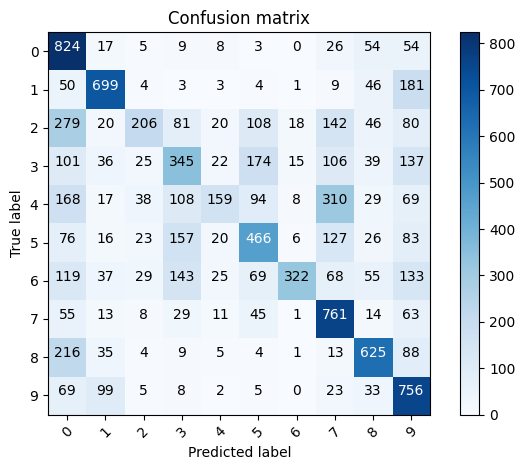

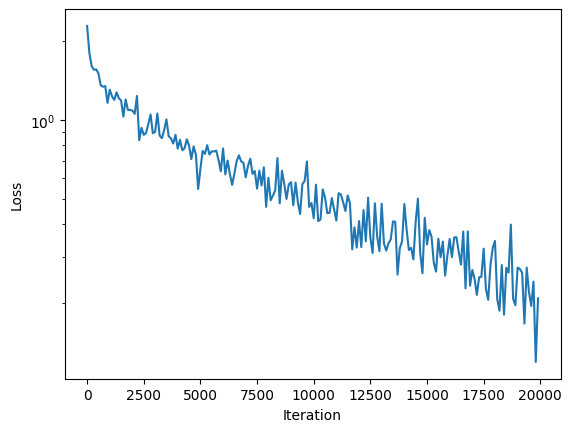

In [ ]:
outputs = model.apply(model.params, test_images, False)
pred_labels = jnp.argmax(outputs,1)
# print(test_labels)
# print(pred_labels)
M = confusion_matrix(test_labels, pred_labels)
plt.figure()
plot_confusion_matrix(M, classes=np.arange(10), normalize=False)

plt.figure()
plt.plot(jnp.arange(len(model.loss_log)) * 100,jnp.array(model.loss_log))
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.show()

## Part 2

In [15]:
aug_train_dataset = AugDataGenerator(train_images, one_hot_labels, batch_size=128)
data = iter(aug_train_dataset)
batch = next(data)

In [16]:
inputs, labels = batch
print(inputs.shape)
print(labels.shape)
print(labels)
print(inputs)

(128, 32, 32, 3)
(128, 10)
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 1. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
Array(shape=(128, 32, 32, 3), dtype=float32)


In [17]:
large_arch = ConvNet(
    out_channels=[32,64,128],
    dense_layers=[120,60,10],
    activation = nn.relu
    )
large_model = CNNclassifier(large_arch)


                                ConvNet Summary                                 
┏━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ path    ┃ module  ┃ inputs            ┃ outputs           ┃ params           ┃
┡━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│         │ ConvNet │ float32[32,32,3]  │ float32[10]       │                  │
├─────────┼─────────┼───────────────────┼───────────────────┼──────────────────┤
│ Conv_0  │ Conv    │ float32[32,32,3]  │ float32[32,32,32] │ bias:            │
│         │         │                   │                   │ float32[32]      │
│         │         │                   │                   │ kernel:          │
│         │         │                   │                   │ float32[5,5,3,3… │
│         │         │                   │                   │                  │
│         │         │                   │                   │ 2,432 (9.7 KB)   │
├─────────┼─────────┼──────

In [19]:
# Train model
large_model.train(aug_train_dataset, nIter=20000)

  0%|          | 1/20000 [00:00<2:11:29,  2.53it/s, loss=2.2765317]W1121 22:53:35.956561    1779 stream_executor_allocator.cc:68] could not allocate pinned host of size: 1073741824 (INTERNAL: [0] Failed to allocate 1.00GiB (1073741824 bytes) of pinned host memory: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: === 
external/xla+/xla/stream_executor/cuda/cuda_host_allocator.cc:83
)
W1121 22:53:36.182764    1779 stream_executor_allocator.cc:68] could not allocate pinned host of size: 966367488 (INTERNAL: [0] Failed to allocate 921.60MiB (966367488 bytes) of pinned host memory: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: === 
external/xla+/xla/stream_executor/cuda/cuda_host_allocator.cc:83
)
W1121 22:53:36.401167    1779 stream_executor_allocator.cc:68] could not allocate pinned host of size: 869730560 (INTERNAL: [0] Failed to allocate 829.44MiB (869730560 bytes) of pinned host memory: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Loca

KeyboardInterrupt: 

# Problem 3 (Vision Transformer + Layer Normalization) [20 points]

This problem uses the same [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html) as Problem 2.

The goal is **not** to train an accurate model. We will use a small but very deep [Vision Transformer](https://arxiv.org/pdf/2010.11929) (ViT) to see how difficult deep transformers are to train, and why layer normalization is important. Do not expect accuracies close to the CNNs from Problem 2.

These tutorials may be helpful:
- [Transformers and Multi-Head Attention](https://uvadlc-notebooks.readthedocs.io/en/latest/tutorial_notebooks/tutorial6/Transformers_and_MHAttention.html)
- [Vision Transformers](https://uvadlc-notebooks.readthedocs.io/en/latest/tutorial_notebooks/JAX/tutorial15/Vision_Transformer.html)

## Part 1 (Implementation)

You are given `FFN` and `SelfAttention`, and skeletons of `Encoder`, `PositionalEmbedding`, and `VisionTransformer`. Complete the following:

**Note:** The given code is **not** written to accept a batch dimension. It operates on a single image of shape `(32, 32, 3)`, or a single sequence of tokens of shape `(N, d)`. If you use the given code, `vmap` the forward pass over the batch dimension.

**`Encoder`:** implement the residual connections and layer norm placement for all three options of `layer_norm`:

| `layer_norm` | Encoder block |
|---|---|
| `"Pre"` | $x \leftarrow x + \mathrm{MHSA}(\mathrm{LN}(x))$, then $x \leftarrow x + \mathrm{FFN}(\mathrm{LN}(x))$ |
| `"Post"` | $x \leftarrow \mathrm{LN}(x + \mathrm{MHSA}(x))$, then $x \leftarrow \mathrm{LN}(x + \mathrm{FFN}(x))$ |
| `None` | $x \leftarrow x + \mathrm{MHSA}(x)$, then $x \leftarrow x + \mathrm{FFN}(x)$ |

**`PositionalEmbedding`:** implement the sinusoidal positional embedding for $N$ tokens of dimension $d$:

$$ \mathrm{PE}(p) = \left[\sin(p\,\omega_0), \dots, \sin(p\,\omega_{d/2-1}), \cos(p\,\omega_0), \dots, \cos(p\,\omega_{d/2-1})\right], \quad \omega_i = 10000^{-i/(d/2)}, \quad p = 0, \dots, N-1 $$

**`VisionTransformer`:**
1. Split each 32x32x3 image into non-overlapping 4x4 patches and flatten each patch, giving 64 tokens of dimension 48.
2. Linearly embed each token to the hidden dimension.
3. Prepend a learnable class token, giving 65 tokens.
4. Add the positional embedding.
5. Pass the tokens through the stack of encoder blocks.
6. Take the class token, apply a final layer norm (Pre-LN only), and map it to the 10 class logits with a linear layer.

## Part 2 (Training)

Train three ViTs with patch size 4, hidden dimension 64, 4 heads, an MLP ratio of 2, and **20 encoder blocks**:
- without layer normalization
- with Pre-layer normalization
- with Post-layer normalization

Use the multi-class cross entropy loss and the [Adam](https://arxiv.org/pdf/1412.6980) optimizer with a constant learning rate of 1e-03. Train each model for 1000 steps with a batch size of 128.

**Note:** You must write out the cross entropy loss yourself. Using `optax.softmax_cross_entropy` is **not** allowed.

## Deliverables:

1. Plot the training losses on a log scale: Pre-LN and Post-LN on one figure, and no layer normalization on a separate figure.
2. Report the confusion matrix and accuracy on both the training set and the test set, for all three models.
3. Report your findings: describe how the three models behave during training, and explain why layer normalization, and its placement, matters for training deep transformers.

If implemented correctly, the loss without layer normalization should blow up, the Post-LN loss should stay flat, and Pre-LN should begin to outperform Post-LN, with a noticeably higher accuracy.

See also the [Pre-LN paper](https://arxiv.org/pdf/2002.04745) for the difference between Pre-LN and Post-LN, which is also visualized below. 

<div align="center">
<img src="layer_norm.png" width="600">
</div>

## Part 3 (Reading Only: Transformers, RNNs, and Linear Attention)

**There is nothing to implement or submit for this part.** It connects the attention you implemented above to the RNNs in Problem 4.

For a single head, the self-attention output for token $i$ is a weighted average of the values,

$$
y_i = \frac{\sum_{j=1}^{N} \exp\!\big(q_i^\top k_j / \sqrt{d_h}\big)\, v_j}{\sum_{j=1}^{N} \exp\!\big(q_i^\top k_j / \sqrt{d_h}\big)},
$$

so every token compares itself with every other token. This costs $O(N^2)$ in the sequence length $N$. That is cheap for our 65 tokens, but it dominates for long sequences or high-resolution images.

**Linear attention.** [Katharopoulos et al. (2020)](https://arxiv.org/pdf/2006.16236) replace the similarity $\exp(q^\top k)$ with a dot product of feature maps, $\phi(q)^\top\phi(k)$, where $\phi$ is a positive function (they use $\phi(x) = \mathrm{elu}(x) + 1$). The sums then no longer depend on $i$:

$$
y_i = \frac{\phi(q_i)^\top \sum_{j} \phi(k_j)\, v_j^\top}{\phi(q_i)^\top \sum_{j} \phi(k_j)},
$$

so $\sum_j \phi(k_j) v_j^\top$ and $\sum_j \phi(k_j)$ can be computed once and reused for every token, bringing the cost down to $O(N)$.

**Transformers are RNNs.** In a causal model (each token only attends to earlier tokens, $j \le i$, as in language models), these sums can be built up one token at a time:

$$
S_i = S_{i-1} + \phi(k_i)\, v_i^\top, \qquad z_i = z_{i-1} + \phi(k_i), \qquad y_i = \frac{S_i^\top \phi(q_i)}{z_i^\top \phi(q_i)}.
$$

This is a recurrent network: a fixed-size state $(S_i, z_i)$ updated once per step, like $(h_t, c_t)$ in an LSTM. Compare the state update to the LSTM cell update in Problem 4, $c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$. Linear attention is an additive memory with the forget gate fixed at $f_t = 1$, so it never forgets. Many recent sequence models, such as RetNet and Mamba, can be viewed as adding a learned decay or gate to this state, which brings back the LSTM's ability to forget.

**The trade-off.** Softmax attention keeps every past token and can look any of them up exactly, but its memory and cost grow with $N$. An RNN, or linear attention, compresses the whole history into a fixed-size state. That is cheaper, but it is lossy.

Note that the ViT in this problem is **not** causal: the class token attends to every patch at once. The $O(N)$ cost reduction still applies, but the step-by-step RNN view is specific to causal attention.


In [ ]:
class FFN(nn.Module):
    hidden_dim: int
    output_dim: int
    kernel_init: Callable = xavier_uniform()

    @nn.compact
    def __call__(self, x):
        x = nn.Dense(self.hidden_dim, kernel_init=self.kernel_init)(x)
        x = nn.gelu(x)
        x = nn.Dense(self.output_dim, kernel_init=self.kernel_init)(x)
        return x


class SelfAttention(nn.Module):
    num_heads: int
    hidden_dim: int
    kernel_init: Callable = xavier_uniform()

    def setup(self):
        self.scale = 1.0 / jnp.sqrt(self.hidden_dim / self.num_heads)
        self.get_qkv = nn.Dense(3*self.hidden_dim, kernel_init=self.kernel_init, use_bias=False)
        self.o_proj = nn.Dense(self.hidden_dim, kernel_init=self.kernel_init)

    def __call__(self, x):
        qkv = self.get_qkv(x)
        q, k, v = rearrange(qkv, "n (h split dh) -> split h n dh", split=3, h=self.num_heads)

        scores = self.scale * jnp.einsum("hnd, hmd -> hnm", q, k)
        attn = nn.softmax(scores, axis=-1)

        output = jnp.einsum("hnm, hmd -> hnd", attn, v)
        output = rearrange(output, "h n dh -> n (h dh)")
        return self.o_proj(output)

In [ ]:
class Encoder(nn.Module):
    num_heads: int
    hidden_dim: int
    mlp_ratio: int
    layer_norm: Literal[None, "Pre", "Post"]

    def setup(self):
        self.SelfAttention = SelfAttention(self.num_heads, self.hidden_dim)
        self.FFN = FFN(self.mlp_ratio * self.hidden_dim, self.hidden_dim)

        if self.layer_norm is None:
            self.LN1 = # Fill in
            self.LN2 = # Fill in
        else:
            self.LN1 = # Fill in
            self.LN2 = # Fill in

    def __call__(self, x):
        if self.layer_norm == "Pre":
            # Call self.SelfAttention, self.FNN and self.L1{1,2} here
        else:
            # Call self.SelfAttention, self.FNN and self.L1{1,2} here
        return x
    

class PositionalEmbedding(nn.Module):
    hidden_dim: int

    def setup(self):
        self.omega = # Fill in

    def __call__(self, N):
        position = jnp.arange(N, dtype=jnp.float32)[:, None]
        phase = position * self.omega 
        emb = jnp.concatenate((jnp.sin(phase), jnp.cos(phase)), axis=-1)
        return emb
    

def patchify(x, patch_size):
    # See `img_to_patch` in https://uvadlc-notebooks.readthedocs.io/en/latest/tutorial_notebooks/JAX/tutorial15/Vision_Transformer.html
    # It will not work out of the box, as it includes a batch dimension
    return x

class VisionTransformer(nn.Module):
    patch_size: int
    num_classes: int
    num_heads: int
    hidden_dim: int
    mlp_ratio: int
    encoder_depth: int
    layer_norm: Literal[None, "Pre", "Post"]
    kernel_init: Callable = xavier_uniform()

    @nn.compact
    def __call__(self, x):
        cls_token = self.param("cls_token", normal(stddev=1.0), (1, self.hidden_dim))

        x = # patchify
        x = # Embed

        x = jnp.concatenate((cls_token, x), axis=-2)
        x = # Add positional encoding here

        for _ in range(self.encoder_depth):
            x = Encoder(self.num_heads, self.hidden_dim, self.mlp_ratio, self.layer_norm)(x)

        x = # extract cls_token
        if self.layer_norm == "Pre":
            x = # Fill in
        x = # Embed
        return x

# Problem 4 (RNNs) [20 points]

In this problem you will implement a [long short-term memory](https://colah.github.io/posts/2015-08-Understanding-LSTMs/) (LSTM) network from scratch and use it to forecast a time series. The setup and data are the same as the [Flax RNN notebook](https://github.com/PredictiveIntelligenceLab/ENM5310/blob/main/notebooks/Flax_RNN.ipynb) from class, except that you must write the LSTM cell yourself.

**Note:** Using `nn.LSTMCell`, `nn.OptimizedLSTMCell`, `nn.RNN`, or any other built-in recurrent cell is **not** allowed.

## Data

Sample $y(t) = \sin(\pi t)$ at $t = 0, 0.1, 0.2, \dots, 9.9$, giving 100 points. Use the first 2/3 of the series for training, and normalize the whole series with the mean and standard deviation of the training portion.

Each input is a window of the previous $L=5$ values and the target is the next value, $(y_{t-5}, \dots, y_{t-1}) \mapsto y_t$, so a batch of inputs has shape `(batch, 5, 1)` and a batch of targets has shape `(batch, 1)`. Only train on windows whose target lies in the training portion.

**Note:** The class notebook normalizes the whole series and then creates windows from all of it, so it actually trains on all 100 points. Do **not** do that here: compute the normalization statistics from the training portion only, and only train on windows whose target lies in the first 2/3 of the series.

## Part 1 (Implementation)

**LSTM cell:** implement a Flax module that takes the previous state $(h_{t-1}, c_{t-1})$ and the input $x_t\in\mathbb{R}^D$ and returns the new state $(h_t, c_t)$, using

$$
\begin{aligned}
f_t &= \mathrm{sigmoid}\big(W_f h_{t-1} + U_f x_t + b_f\big) && \text{forget gate}\\
i_t &= \mathrm{sigmoid}\big(W_i h_{t-1} + U_i x_t + b_i\big) && \text{input gate}\\
o_t &= \mathrm{sigmoid}\big(W_o h_{t-1} + U_o x_t + b_o\big) && \text{output gate}\\
\tilde c_t &= \tanh\big(W_c h_{t-1} + U_c x_t + b_c\big) && \text{candidate}\\
c_t &= f_t \odot c_{t-1} + i_t \odot \tilde c_t\\
h_t &= o_t \odot \tanh(c_t)
\end{aligned}
$$

where $h_t, c_t\in\mathbb{R}^H$, $W_\ast\in\mathbb{R}^{H\times H}$, $U_\ast\in\mathbb{R}^{H\times D}$, and $b_\ast\in\mathbb{R}^H$.

**LSTM:** starting from $h_0 = c_0 = 0$, apply the cell over the $L=5$ steps of the input window (a Python `for` loop, `jax.lax.scan`, or `nn.scan` are all fine), then map the final hidden state $h_L$ to the 1-dimensional prediction with a linear layer.

## Part 2 (Training)

Use a hidden dimension of $H=4$. Train with the mean squared error loss and the [Adam](https://arxiv.org/pdf/1412.6980) optimizer with an exponential decay learning rate schedule (`optax.exponential_decay`), starting at $10^{-3}$ and decaying by a factor of 0.9 every 1000 steps. Train for 40000 steps with a batch size of 32.

After training, forecast the whole series by **feeding the model's predictions back in as inputs**: start from the first window of 5 true values, predict the next value, append the prediction to the window and drop the oldest value, and repeat until the end of the series. De-normalize the predictions before comparing them to the true series.

## Deliverables

1. Plot the training loss with the y-axis on a log scale.
2. Plot the forecast against the true series, with a vertical line marking the end of the training data, and report the relative $L^2$ error (in %) between the forecast and the true series.
3. Report the number of trainable parameters in your model, and verify that it equals $4H(H+D+1) + (H+1)$ (LSTM cell plus linear output layer).

# Problem 5 (Physics-Informed Neural Networks) [20 points]

The KdV equation is given by

$$
\begin{cases}
    u_t + \eta uu_x + \mu^2 u_{xxx} = 0, \quad (t,x)\in[0,1]\times[-1,1] \\
    u(0,x) = \cos(\pi x), \quad x\in[-1,1] \\
    u(t,-1) = u(t,1), \quad t\in[0,1]
\end{cases}
$$

with $\eta=1$ and $\mu=0.022$. Train two Physics-Informed Neural Networks (PINNs) to solve the KdV equation, one with and one without Fourier features.

The true solution can be downloaded from Canvas at `Files/Uploaded Media/KdV.mat`. It contains the solution `usol` on a grid given by `t` and `x`.

## Models

Both PINNs take $(t, x)$ as input and output $u(t,x)$:

- **PINN:** an MLP with **3 hidden layers** of 100 neurons each, using a $\tanh$ activation function, followed by a **linear output layer** with 1 neuron. The full layer sizes are $[2, 100, 100, 100, 1]$.
- **PINN + Fourier features:** the same MLP with Gaussian Fourier features (as in Problem 1) at the beginning of the model. Use 50 frequencies, so $\mathbf{B}\in\mathbb{R}^{2\times50}$, initialize $\mathbf{B}$ with entries drawn from $\mathcal{N}(0, 0.5^2)$ (standard deviation 0.5), and make $\mathbf{B}$ **learnable**. The full layer sizes are $[100, 100, 100, 100, 1]$.

## Loss

Train each model by minimizing the sum of the residual, initial condition, and boundary condition losses, $\mathcal{L} = \mathcal{L}_\text{r} + \mathcal{L}_\text{IC} + \mathcal{L}_\text{BC}$, where

$$
\mathcal{L}_\text{r} = \frac{1}{N_\text{r}}\sum_{i=1}^{N_\text{r}} \left|u_t + \eta uu_x + \mu^2 u_{xxx}\right|^2_{(t_i, x_i)}, \quad
\mathcal{L}_\text{IC} = \frac{1}{N_\text{IC}}\sum_{i=1}^{N_\text{IC}} \left|u(0,x_i) - \cos(\pi x_i)\right|^2, \quad
\mathcal{L}_\text{BC} = \frac{1}{N_\text{BC}}\sum_{i=1}^{N_\text{BC}} \left|u(t_i,-1) - u(t_i,1)\right|^2
$$

- **Residual:** $N_\text{r}=4096$ collocation points $(t_i, x_i)$, sampled uniformly at random from $[0,1]\times[-1,1]$ at every step.
- **Initial condition:** $N_\text{IC}=500$ equally spaced points $x_i\in[-1,1]$ (fixed is fine here not resampled).
- **Boundary condition:** $N_\text{BC}=500$ equally spaced points $t_i\in[0,1]$ (fixed is fine here not resampled).

## Training

Use the [Adam](https://arxiv.org/pdf/1412.6980) optimizer with a warmup exponential decay learning rate schedule ([`optax.warmup_exponential_decay_schedule`](https://optax.readthedocs.io/en/latest/api/optimizer_schedules.html#optax.warmup_exponential_decay_schedule)). The learning rate starts at $10^{-8}$, warms up to a peak of $10^{-3}$ over the first 5000 steps, and then decays by a factor of 0.9 every 1000 steps. Train each model for 50000 steps.

**HINT:** Though not required, to efficiently compute the derivatives $u_x$, $u_{xx}$, and $u_{xxx}$ it may be useful to use [`jax.experimental.jet`](https://docs.jax.dev/en/latest/jax.experimental.jet.html) with `series=[[1.0, 0.0, 0.0]]`. For example, for a network $u(t, x)$ evaluated at a single point $(t, x)$:

```python
from jax.experimental.jet import jet

u, (u_x, _, u_xxx) = jet(lambda x: self.neural_net(params, t, x), (x,), [[1.0, 0.0, 0.0]])
```

## Deliverables

1. Plot the residual, initial condition, and boundary condition losses as a function of steps, with the y-axis on a log scale. Use one figure per loss, with both models on each figure.
2. For both models, plot the true solution, the predicted solution, and the pointwise absolute error between the two, and report the relative $L^2$ error (in %) between the true and predicted solutions.

# Problem 6 [10 bonus points]
Submit a two-page summary of your proposed final project. Make sure you clearly articulate the following:

- An overview of the proposed problem and why it is important.
- What are the challenges to be addressed.
- What is the current state-of-the-art and its potential limitations.
- What is the formal mathematical definition of the problem, and what is the technical approach you will employ.
- What is the potential impact upon the successful completion of the project.

Any figures or references should be included within the 2-page limit. Please upload it as a PDF in Canvas.